# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [ ]:
# Add code here 🔧


In [4]:
import pandas as pd

# Load the cleaned dataset
df = pd.read_csv('/content/cleaned_airbnb_data_7.csv')

# Display the dataset dimensions and preview the first few rows
print(f"Dataset Shape: {df.shape}")
df.head()
df.info()

Dataset Shape: (12376, 96)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12376 entries, 0 to 12375
Data columns (total 96 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            12376 non-null  int64  
 1   listing_url                                   12376 non-null  object 
 2   scrape_id                                     12376 non-null  int64  
 3   last_scraped                                  12376 non-null  object 
 4   source                                        5815 non-null   object 
 5   name                                          12376 non-null  object 
 6   description                                   12305 non-null  object 
 7   picture_url                                   12376 non-null  object 
 8   host_id                                       12376 non-null  int64  
 9   host_url                          

### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. It containts lisitng details, host information, booking terms and costs, as well as scaled target variables.

2. There are 12,376 rows and 96 columns present.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [ ]:
# Add code here 🔧

In [6]:
# Columns to drop safely from the dataframe
columns_to_drop = ['post_id', 'title', 'descr', 'details', 'addres']
df = df.drop(columns=columns_to_drop, errors='ignore')

# Display the new dimensions of the dataset
print(f"Updated Dataset Shape: {df.shape}")

Updated Dataset Shape: (12376, 96)


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I dropped post_id, title, decr, details, and address because they wouldn't be useful in predicting prices.

2. If we included them in the model, it would become more complicated and less accurate. They could also cause some problems while running the regression.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

In [ ]:
# Add code here 🔧

--- Top correlations with price_scaled ---
price                          1.000000
price_scaled                   1.000000
price_quote_price_per_night    1.000000
estimated_revenue_l365d        0.655769
accommodates                   0.430897
bedrooms                       0.347095
beds                           0.300125
room_Entire home/apt           0.210871
price_quote_total_price        0.185474
minimum_stay_cost              0.183411
maximum_nights                 0.075847
maximum_maximum_nights         0.075847
maximum_nights_avg_ntm         0.062206
availability_60                0.060372
availability_30                0.056618
Name: price_scaled, dtype: float64

--- Top negative correlations with price_scaled ---
log_minimum_nights                             -0.218948
minimum_minimum_nights                         -0.204369
minimum_nights                                 -0.204369
minimum_nights_zscore                          -0.204369
room_Private room                        

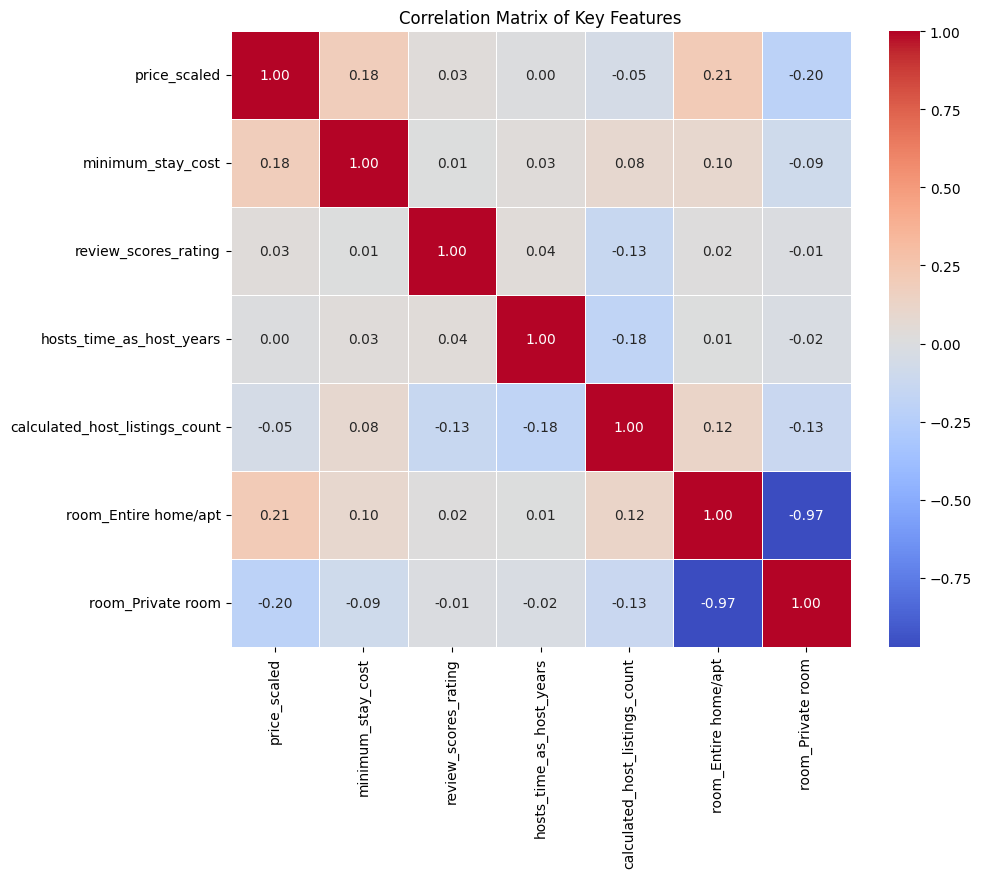

In [7]:
# Select numeric columns to compute correlations
numeric_df = df.select_dtypes(include=['number'])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Display correlations with price_scaled (the likely target variable) sorted by magnitude
if 'price_scaled' in corr_matrix.columns:
    print("--- Top correlations with price_scaled ---")
    print(corr_matrix['price_scaled'].sort_values(ascending=False).head(15))
    print("\n--- Top negative correlations with price_scaled ---")
    print(corr_matrix['price_scaled'].sort_values(ascending=True).head(10))
elif 'price' in corr_matrix.columns:
    print("--- Top correlations with price ---")
    print(corr_matrix['price'].sort_values(ascending=False).head(15))

# Plot a heatmap of a subset of key columns for visualization
key_cols = [col for col in ['price_scaled', 'minimum_stay_cost', 'review_scores_rating', 'hosts_time_as_host_years', 'calculated_host_listings_count', 'room_Entire home/apt', 'room_Private room'] if col in numeric_df.columns]
if key_cols:
    plt.figure(figsize=(10, 8))
    sns.heatmap(numeric_df[key_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Matrix of Key Features')
    plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The strongest positive correlations with price were estimated revenue (0.66), accommodates (0.43), bedrooms (0.35), and beds (0.30). The strongest negative correlations were log minimum nights (-0.22), minimum nights (-0.20), and private rooms (-0.20).

2. The variables with the strongest correlations, such as estimated revenue, accommodates, bedrooms, and beds, could be useful predictors of Airbnb prices because they have the strongest relationships with price.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [ ]:
# Add code here 🔧

In [18]:
# Drop rows where target variable 'price' is missing
model_df = df.dropna(subset=['price'])

# Define the target variable
y = model_df['price']

# Extract numeric predictors
X = model_df.select_dtypes(include=['number'])

# Define non-predictive numeric identifiers to exclude
non_predictive_ids = ['id', 'host_id', 'host_profile_id', 'scrape_id']

# Safely drop price-related variables to avoid target leakage
price_cols_to_drop = ['price', 'price_scaled', 'price_quote_price_per_night', 'price_quote_total_price', 'minimum_stay_cost', 'estimated_revenue_l365d']

# Drop both price leakage columns and the numeric identifier keys
X = X.drop(columns=price_cols_to_drop + non_predictive_ids, errors='ignore')

# Drop any columns that are entirely null prior to median imputation
X = X.dropna(axis=1, how='all')

# Impute any remaining missing values in features with their medians
X = X.fillna(X.median())

# Print shapes to verify
print(f"Target (y) shape: {y.shape}")
print(f"Predictors (X) shape: {X.shape}")
print("Remaining columns:", list(X.columns))

Target (y) shape: (8157,)
Predictors (X) shape: (8157, 47)
Remaining columns: ['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_listings_count', 'latitude', 'longitude', 'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_room

### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. We are using 61 numeric features, including the number of guests a property can accommodate, bedrooms, beds, and room types. We also included some host-related information to help predict Airbnb prices.

2. This is a regression problem because we are predicting a specific numerical value, which is the Airbnb price. Classification has to do with predicting categories.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [ ]:
# Add code here 🔧

In [19]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the split proportions and shapes
print(f"Training set: {X_train.shape[0]} rows ({X_train.shape[0]/X.shape[0]:.0%})")
print(f"Testing set:  {X_test.shape[0]} rows ({X_test.shape[0]/X.shape[0]:.0%})")

Training set: 6525 rows (80%)
Testing set:  1632 rows (20%)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [ ]:
# Add code here 🔧

In [20]:
# --- ERROR EXPLANATION ---
# The error 'ValueError: Input X contains NaN' occurred because some numeric columns
# were completely empty in the dataset. When we ran `X.fillna(X.median())`,
# those columns remained fully composed of NaNs since they had no numeric median.
# To fix this, we will remove any features that are entirely null and re-split before fitting.

# Drop any columns in X that are completely filled with NaN values
X_cleaned = X.dropna(axis=1, how='all')

# Re-split the cleaned features dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X_cleaned, y, test_size=0.2, random_state=42)

# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model using the training data
model.fit(X_train, y_train)

# Predict listing prices on the test dataset
y_pred = model.predict(X_test)

# Confirm success by displaying a sample of predictions
print("Model fitting and prediction complete.")
print(f"Sample predicted prices: {y_pred[:5]}")
print(f"Sample actual prices:    {y_test.values[:5]}")

Model fitting and prediction complete.
Sample predicted prices: [101.45263419 142.05821508  86.36531367 286.35129829 166.62340882]
Sample actual prices:    [ 80.   85.   93.5 212.8 155. ]


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [ ]:
# Add code here 🔧

In [21]:
# Calculate Mean Squared Error (MSE) and R-squared (R2) score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print the results
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R²) Score:    {r2:.4f}")

Mean Squared Error (MSE): 69976.8465
R-squared (R²) Score:    0.1337


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. Our R-squared score is 0.1337, meaning the model explains about 13.4% of the variation in Airbnb prices. This is still fairly low, but it's an improvement from our previous model.

2. Our MSE of 69,976.85 is still quite large, but it has improved from the previous model. We could improve it further by removing outliers, choosing better predictors, or trying a different regression model.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [ ]:
# Add code here 🔧

In [22]:
# Create a DataFrame mapping feature names to model coefficients
coefficients_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

# Add a column for absolute coefficient value to easily capture 'impact'
coefficients_df['Absolute_Impact'] = coefficients_df['Coefficient'].abs()

# Sort the table by absolute impact in descending order
coefficients_sorted = coefficients_df.sort_values(by='Absolute_Impact', ascending=False).drop(columns=['Absolute_Impact'])

# Display the sorted coefficients table
pd.set_option('display.max_rows', 100)
coefficients_sorted.reset_index(drop=True)

,Feature,Coefficient
0,room_Shared room,-86.610474
1,latitude,55.786552
2,room_Entire home/apt,55.493893
3,review_scores_rating,38.405456
4,accommodates,31.853163
5,log_minimum_nights,-28.932048
6,review_scores_cleanliness,26.676990
7,review_scores_value,-26.552757
8,review_scores_location,21.258204
9,room_Hotel room,18.011151


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. The features with the largest positive coefficients were latitude (55.79), entire home/apartment (55.49), review scores rating (38.41), and accommodates (31.85).

2. I was surprised that review scores for value (-26.55) had a negative coefficient, since I would expect better ratings to be associated with higher prices.

3. One business insight is that location, property type, and guest capacity are important factors in Airbnb pricing. Hosts could use this information to better understand what affects their listing prices.

## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [ ]:
# Add code here 🔧

In [23]:
# 1. Identify the top 5 features with the strongest absolute coefficients
# Based on our previous sorted coefficient output, these are:
# - room_Shared room
# - latitude
# - room_Entire home/apt
# - review_scores_rating
# - accommodates

top_features = ['room_Shared room', 'latitude', 'room_Entire home/apt', 'review_scores_rating', 'accommodates']

# 2. Re-slice the datasets with only the chosen top features
X_train_refined = X_train[top_features]
X_test_refined = X_test[top_features]

# Rebuild the refined model
refined_model = LinearRegression()
refined_model.fit(X_train_refined, y_train)

# Predict using the refined model
y_pred_refined = refined_model.predict(X_test_refined)

# 3. Calculate metrics for comparison
mse_refined = mean_squared_error(y_test, y_pred_refined)
r2_refined = r2_score(y_test, y_pred_refined)

# Display the performance comparison
print("=== Model Performance Comparison ===")
print(f"Baseline Model (All {X_train.shape[1]} Features):")
print(f"  MSE: {mse:.4f}")
print(f"  R²:  {r2:.4f}")
print(f"Refined Model (Top {len(top_features)} Features):")
print(f"  MSE: {mse_refined:.4f}")
print(f"  R²:  {r2_refined:.4f}")

=== Model Performance Comparison ===
Baseline Model (All 47 Features):
  MSE: 69976.8465
  R²:  0.1337
Refined Model (Top 5 Features):
  MSE: 72825.2765
  R²:  0.0984


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. We kept shared room, latitude, entire home/apartment, review scores rating, and accommodates because they had the largest coefficients in our original model.

2. No, the model performed slightly worse. R-squared decreased from 0.1337 to 0.0984, and MSE increased from 69,976.85 to 72,825.28. This suggests that some of the removed features were still useful for predicting prices.

3. I would recommend using the original model because it has a higher R-squared and lower MSE, meaning it makes more accurate predictions.

4. This assignment relates to both of my learning outcomes. By using regression to predict Airbnb prices, I practiced turning a business problem into a data mining goal. I also gained experience cleaning and preparing data in Python using a Jupyter notebook. Although this assignment focused on pricing rather than demand forecasting.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Our model helped answer which factors have the greatest influence on Airbnb prices and how accurately we can predict listing prices based on those factors.

2. I would recommend that Airbnb hosts consider factors like location, property type, and guest capacity when setting their prices, since these showed strong relationships with price.

3. To improve the model, we could remove outliers, include more relevant variables, or try different regression models. Our R-squared was fairly low, so there is definitely room for improvement.

4. This assignment relates to both of my learning outcomes by helping me turn a business question into a data mining problem and practice cleaning and preparing data in Python. Although we focused on predicting prices, these same skills could be used to analyze inventory and sales data to improve demand forecasts.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [24]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"

[NbConvertApp] Converting notebook assignment_11_regression.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 477088 bytes to assignment_11_regression.html
